# Stage 3: Waiting for classical messages

**Question:** with quantum memories at A and B, how much quality is lost while they wait for the relay's result?

**Timing.** A and B sit at distance *L*/2 from the relay. A photon takes *L*/2 ÷ (200,000 km/s) to reach the relay,
and the 2-bit result takes the same time to come back. So each attempt keeps the memories waiting a round trip,
$t_\text{attempt} = L / c_\text{fibre}$ (about 5 µs per km of A–B distance). If the attempt fails (photon lost), they try again,
and the memory holding an earlier success keeps waiting.

**Memory model.** Stored qubits *dephase*: their quantum coherence decays as $e^{-t/T_2}$, where $T_2$ is the memory's coherence time.
In PennyLane this is `qml.PhaseDamping`.

**Prediction.** Dephasing leaves Z-basis correlations untouched but shrinks X-basis correlations, so
$\langle ZZ\rangle = w$ and $\langle XX\rangle = w\,e^{-2t/T_2}$. In QKD terms, memory errors appear *only in the X basis*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qnet import physics as P, quantum as Q, plotstyle as S
S.apply()

In [2]:
swap_corr = Q.make_swap_circuit("corr")
w_link = P.DEFAULTS["w_source"]     # assume good links; isolate the memory effect
t = 1e-3; T2 = 10e-3
xx, yy, zz = swap_corr(w_link, w_link, wait=t, T2=T2)
print(f"<ZZ> = {float(zz):.4f} (theory {w_link**2:.4f})")
print(f"<XX> = {float(xx):.4f} (theory {w_link**2*np.exp(-2*t/T2):.4f})")

<ZZ> = 0.9604 (theory 0.9604)
<XX> = 0.7863 (theory 0.7863)


T₂ = 1 ms   : X-basis QBER below 11% up to ~6 km
T₂ = 10 ms  : X-basis QBER below 11% up to ~36 km
T₂ = 100 ms : X-basis QBER below 11% up to ~94 km
T₂ = 1 s    : X-basis QBER below 11% up to ~150 km


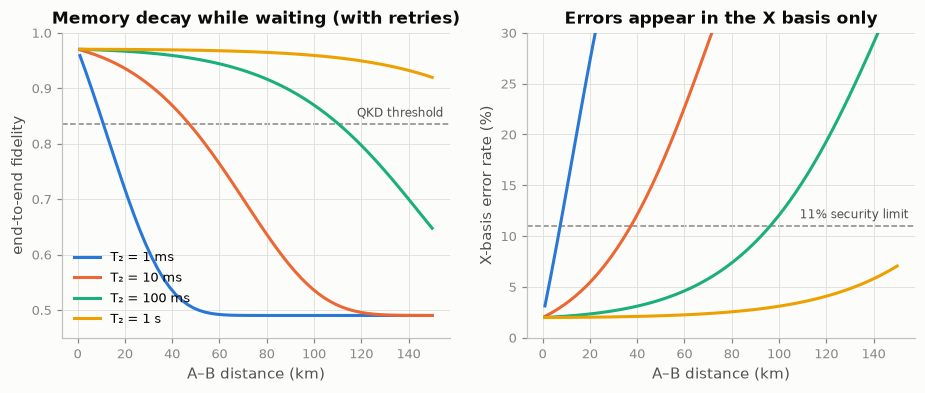

In [3]:
def wait_time(L_km, retries=True):
    t_round = P.classical_delay(L_km)               # one attempt = L / c
    if not retries:
        return t_round
    p = 0.5 * P.DEFAULTS["eta_det"] * P.fibre_transmission(L_km / 2)   # half-link success probability
    return t_round / p                              # average number of attempts x round trip (approximation)

L = np.linspace(1, 150, 60)
T2s = [1e-3, 10e-3, 100e-3, 1.0]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
summary = {}
for T2 in T2s:
    F, Qx = [], []
    for Lk in L:
        xx, yy, zz = swap_corr(w_link, w_link, wait=wait_time(Lk), T2=T2)
        F.append(Q.fidelity_from_corr(xx, yy, zz)); Qx.append((1 - xx) / 2)
    lab = f"T₂ = {T2*1e3:g} ms" if T2 < 1 else f"T₂ = {T2:g} s"
    ax[0].plot(L, F, label=lab); ax[1].plot(L, np.array(Qx) * 100, label=lab)
    ok = L[np.array(Qx) < 0.11]
    summary[lab] = ok.max() if len(ok) else 0
S.threshold(ax[0], 0.835, "QKD threshold")
ax[0].set(xlabel="A–B distance (km)", ylabel="end-to-end fidelity", title="Memory decay while waiting (with retries)", ylim=(0.45, 1))
S.threshold(ax[1], 11, "11% security limit")
ax[1].set(xlabel="A–B distance (km)", ylabel="X-basis error rate (%)", title="Errors appear in the X basis only", ylim=(0, 30))
ax[0].legend(loc="lower left")
S.save(fig, "03_memory_wait")
for k, v in summary.items():
    print(f"{k:12s}: X-basis QBER below 11% up to ~{v:.0f} km")

## Required memory time for a given distance

For each distance, the smallest $T_2$ that keeps the X-basis error below 11%.
This is a design rule linking the classical control plane (message delay, retry policy) to quantum hardware requirements.

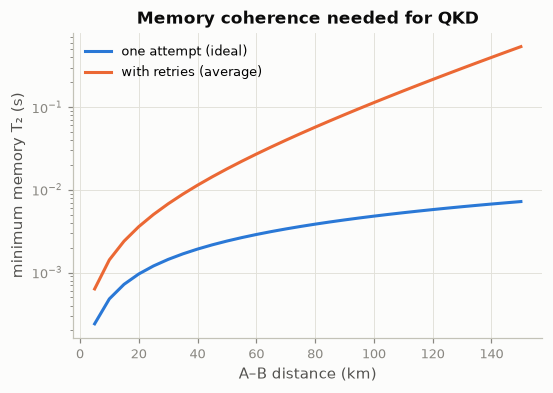

In [4]:
from scipy.optimize import brentq
w2 = w_link ** 2
def qx(T2, Lk, retries):   # analytic, validated above: QBER_X = (1 - w² e^{-2t/T2}) / 2
    return (1 - w2 * np.exp(-2 * wait_time(Lk, retries) / T2)) / 2
Ls = np.linspace(5, 150, 30)
fig, ax = plt.subplots(figsize=(5.5, 3.6))
for retries, lab in [(False, "one attempt (ideal)"), (True, "with retries (average)")]:
    need = [brentq(lambda lt: qx(10**lt, Lk, retries) - 0.11, -9, 6) for Lk in Ls]
    ax.semilogy(Ls, 10 ** np.array(need), label=lab)
ax.set(xlabel="A–B distance (km)", ylabel="minimum memory T₂ (s)", title="Memory coherence needed for QKD")
ax.legend()
S.save(fig, "03_required_T2")

## Takeaways

* Simulated memory dephasing matches the analytic prediction: $\langle ZZ\rangle$ is unchanged and $\langle XX\rangle$ decays.
* Waiting is set by **classical signalling delay** (5 µs/km per round trip) times the **number of retries**,
  and retries grow exponentially with distance. So the classical control plane directly sets the quantum hardware requirement.
* This motivates smarter classical control: cut-offs (discard pairs that waited too long), scheduling, and multiplexing.